<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_12_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

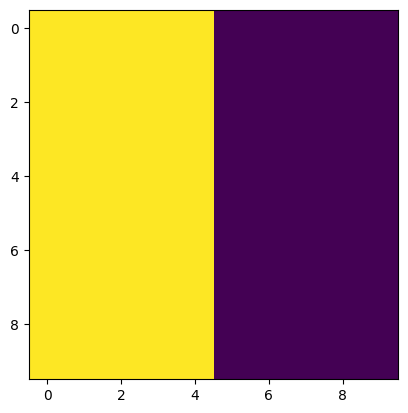

In [3]:
h, v, d = patrones_balanceados(10, 10)
plt.imshow(v)

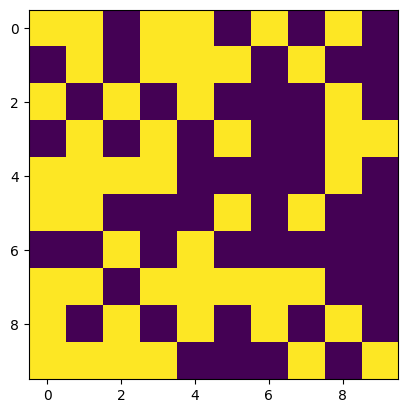

In [4]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (10, 10)))

In [5]:
psiD = np.concat(d)
psiV = np.concat(v)
psiH = np.concat(h)

nx = len(psiD)
ny = len(psiD)
N=nx*ny
Wij=np.zeros((nx, ny))

for i in range(0, nx):
  for j in range(0, ny):
    if(i!=j):
      Wij[i,j] = psiD[i]*psiD[j]+psiV[i]*psiV[j]+psiH[i]*psiH[j]
Wij=Wij/N

In [6]:
S = np.concat(v).reshape(100, 1)
#S = s_ruido.reshape(100, 1)

In [7]:
def campo_efectivo(Wij, estado):
  h_efectivo = Wij@estado
  return h_efectivo

def energia(h_efectivo, estado):
  return np.sum(-0.5*estado*h_efectivo)

In [8]:
hefectivo = campo_efectivo(Wij, S)
E = energia(hefectivo, S)
E

np.float64(-0.48500000000000004)

In [9]:
h = campo_efectivo(Wij, s_ruido)
E = energia(h, s_ruido)


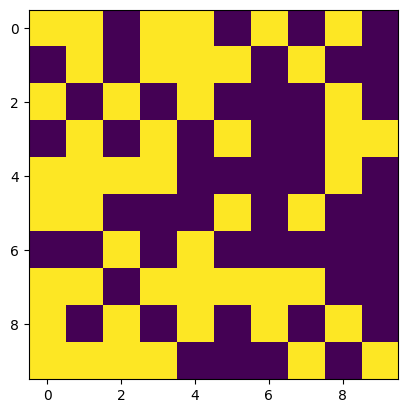

In [10]:
plt.imshow(s_ruido.reshape(10, 10))

In [11]:
n=len(s_ruido)
for i in range(0, 1000):
  index = np.random.randint(0, n)

  h = campo_efectivo(Wij, s_ruido)
 # print(h[index], s_ruido[index])

  if h[index] > 0:
    s_ruido[index] = 1
  else:
    s_ruido[index] = -1

  E = energia(h, s_ruido)
  #print(E)

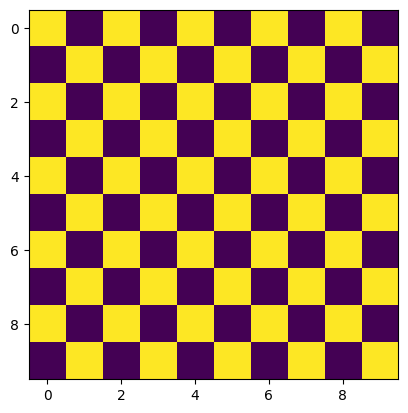

In [12]:
plt.imshow(s_ruido.reshape(10, 10))

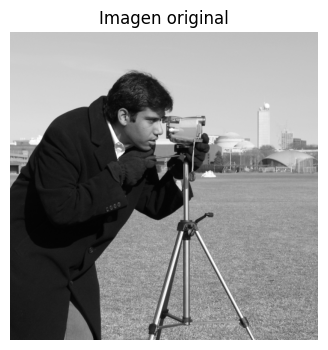

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

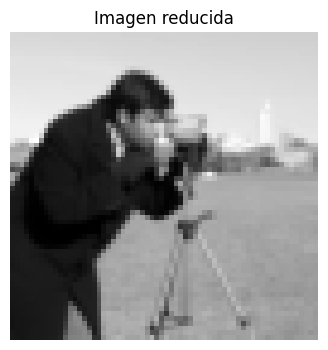

In [14]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

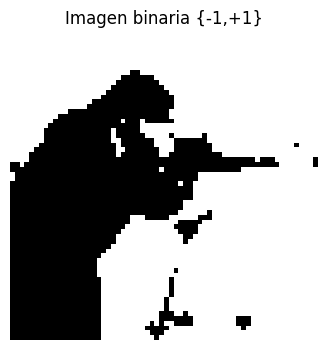

In [15]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [16]:
img_bin

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1]], shape=(64, 64))

In [17]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)


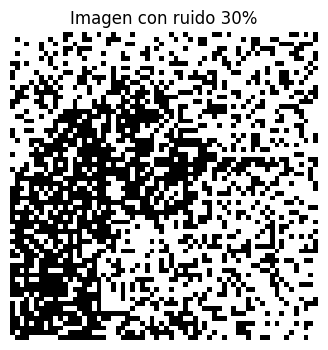

In [18]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

## Implementación paso a paso de la red de Hopfield sobre la imagen del Fotógrafo

A continuación implementamos las 7 funciones solicitadas en la primera celda del laboratorio para la imagen binaria del fotógrafo (`data.camera()` de tamaño $64 \times 64$, es decir $N = 4096$ neuronas). Para que el cálculo sobre $N = 4096$ neuronas sea eficiente, la matriz de pesos se construye de forma vectorizada mediante el producto externo:

$$W = \frac{1}{N} \sum_{\mu=1}^{P} \xi^\mu (\xi^\mu)^T, \qquad w_{ii} = 0$$

Además, en la actualización asincrónica de una sola neurona $i$, como $W$ es simétrica y tiene diagonal nula, el cambio exacto de energía al pasar de $s_i^{\text{ant}}$ a $s_i^{\text{nuevo}}$ es $\Delta E = -(s_i^{\text{nuevo}} - s_i^{\text{ant}})\, h_i$, lo cual permite seguir $E(s)$ en cada iteración y verificarlo con la función `energia_total(W, s)`.

In [19]:
# ============================================================
# 1. Convertir una imagen binaria en un vector de estados {-1, +1}
# ============================================================
def imagen_a_estado(img_bin):
    """Convierte una imagen binaria 2D en un vector 1D con valores en {-1, +1}."""
    return np.where(np.asarray(img_bin).ravel() > 0, 1.0, -1.0)


def estado_a_imagen(estado, shape):
    """Reconstruye la imagen 2D a partir del vector de estados."""
    return np.asarray(estado).reshape(shape)


# ============================================================
# 2. Calcular la matriz de pesos de Hopfield (Regla de Hebb)
# ============================================================
def matriz_pesos_hopfield(patrones):
    """Calcula W_ij = (1/N) * sum_mu xi_i^mu xi_j^mu con W_ii = 0."""
    P_mat = np.atleast_2d(patrones).astype(np.float64)
    N = P_mat.shape[1]
    W = (P_mat.T @ P_mat) / N
    np.fill_diagonal(W, 0.0)
    return W


# ============================================================
# 3. Calcular el campo local que siente una neurona
# ============================================================
def campo_local(W, s, i):
    """Calcula h_i = sum_j w_ij s_j para la neurona i."""
    return float(np.dot(W[i], s))


# ============================================================
# 4. Actualizar el estado de una neurona
# ============================================================
def actualizar_neurona(W, s, i):
    """Actualiza s_i <- sign(h_i) in-place y devuelve (s_i_nuevo, h_i, delta_s)."""
    h_i = campo_local(W, s, i)
    s_anterior = s[i]
    if h_i > 0:
        s[i] = 1.0
    elif h_i < 0:
        s[i] = -1.0
    # Si h_i == 0 se conserva el estado actual
    delta_s = s[i] - s_anterior
    return s[i], h_i, delta_s


# ============================================================
# 5. Calcular la energía total de la red
# ============================================================
def energia_total(W, s):
    """Calcula E(s) = -0.5 * s^T W s."""
    return -0.5 * float(s @ (W @ s))


# ============================================================
# 6. Aplicar ruido a una imagen (o vector de estados)
# ============================================================
def aplicar_ruido(estado, frac=0.30, seed=None):
    """Invierte el signo de una fracción 'frac' de píxeles elegidos al azar."""
    rng = np.random.default_rng(seed)
    s_ruido = np.asarray(estado, dtype=np.float64).copy().ravel()
    N = len(s_ruido)
    n_flip = int(frac * N)
    idx = rng.choice(N, size=n_flip, replace=False)
    s_ruido[idx] *= -1.0
    return s_ruido


# ============================================================
# 7. Recuperar la imagen mediante actualización asincrónica aleatoria
# ============================================================
def recuperar_asincronico(W, s_inicial, max_epocas=10, tol_energia=1e-10,
                          seed=None, pasos_snapshot=None):
    """
    Recupera un patrón visitando aleatoriamente las N neuronas en cada época.
    Se detiene si la imagen deja de cambiar, la energía se estabiliza
    o se alcanza max_epocas.
    """
    rng = np.random.default_rng(seed)
    s = np.asarray(s_inicial, dtype=np.float64).copy().ravel()
    N = len(s)

    E = energia_total(W, s)
    energias = [E]
    pasos_set = set(pasos_snapshot) if pasos_snapshot is not None else set()
    snapshots = [(0, s.copy())] if 0 in pasos_set else []

    paso_global = 0
    epocas_usadas = 0

    for epoca in range(1, max_epocas + 1):
        epocas_usadas = epoca
        E_inicio_epoca = E
        cambios = 0

        # Orden aleatorio de visita para las N neuronas (actualización asincrónica)
        for i in rng.permutation(N):
            _, h_i, delta_s = actualizar_neurona(W, s, i)
            paso_global += 1
            if delta_s != 0.0:
                cambios += 1
                # Cambio exacto de energía: Delta E = -Delta s_i * h_i
                E -= delta_s * h_i
            energias.append(E)

            if paso_global in pasos_set:
                snapshots.append((paso_global, s.copy()))

        # Recálculo exacto al final de la época para evitar deriva numérica
        E = energia_total(W, s)

        if cambios == 0 or abs(E - E_inicio_epoca) < tol_energia:
            break

    return s, np.array(energias), snapshots, {"epocas": epocas_usadas, "pasos": paso_global}


def solapamiento(xi, s):
    """Solapamiento m = (1/N) * xi . s en [-1, 1]."""
    return float(np.dot(xi, s)) / len(xi)

### Recuperación de la imagen del Fotógrafo (30% de ruido)

Aplicamos ahora el flujo completo sobre `img_bin` (el fotógrafo de $64 \times 64$ píxeles): vectorizamos la imagen, construimos $W$, perturbamos el 30% de los píxeles y ejecutamos la recuperación asincrónica aleatoria registrando tanto la evolución visual como la curva de energía $E(s)$.

Número de neuronas N           : 4096
Energía patrón original E(xi)  : -2047.50  (teórico: -2047.50)
Energía imagen con ruido       : -327.82
Energía imagen recuperada      : -2047.50
Épocas ejecutadas / pasos      : 2 / 8192
Solapamiento inicial / final   : 0.4004 -> 1.0000
Coincidencia exacta de píxeles : 100.00%


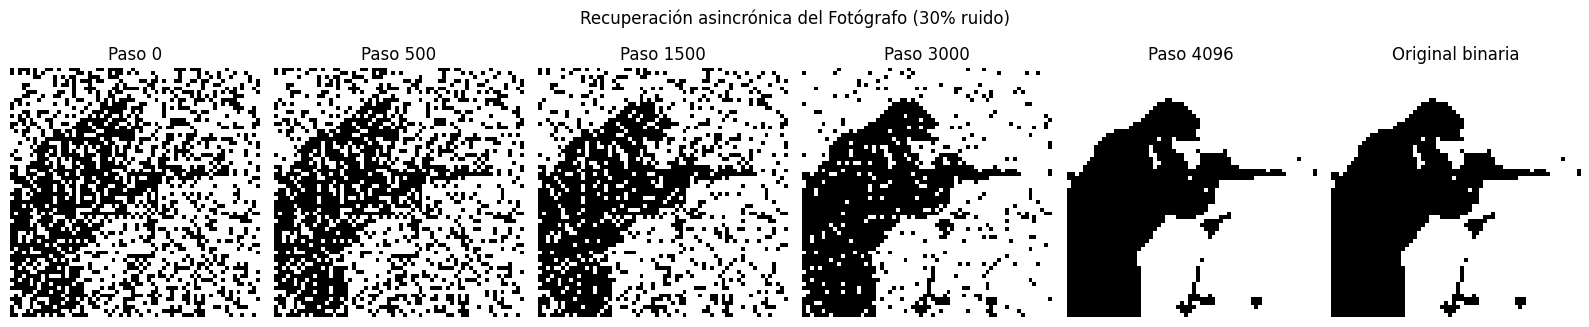

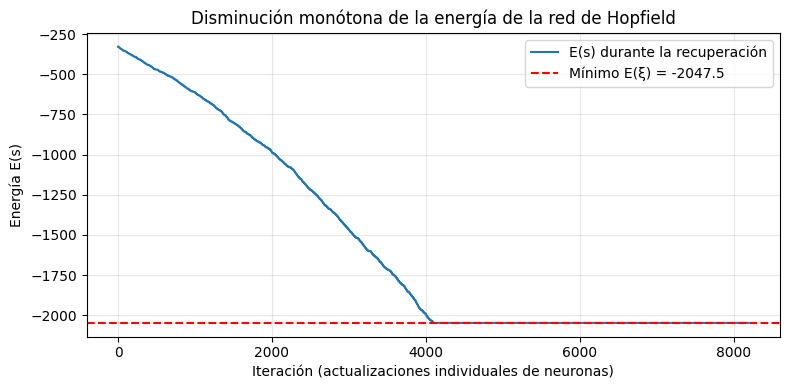

In [20]:
# Paso 1: convertir la imagen binaria del fotógrafo en vector de estados
xi_camera = imagen_a_estado(img_bin)
N_pix = len(xi_camera)

# Paso 2: calcular la matriz de pesos de Hopfield
W_camera = matriz_pesos_hopfield([xi_camera])

# Paso 6: aplicar 30% de ruido
frac_ruido = 0.30
s_ruido_cam = aplicar_ruido(xi_camera, frac=frac_ruido, seed=123)

# Energías iniciales de referencia (Paso 5)
E_patron = energia_total(W_camera, xi_camera)
E_inicial = energia_total(W_camera, s_ruido_cam)

# Paso 7: recuperar mediante actualización asincrónica aleatoria
pasos_vis = [0, 500, 1500, 3000, N_pix]
s_rec, energias, snapshots, info = recuperar_asincronico(
    W_camera, s_ruido_cam, max_epocas=10, seed=42, pasos_snapshot=pasos_vis
)

E_final = energia_total(W_camera, s_rec)
coincidencia = 100.0 * np.mean(s_rec == xi_camera)

print(f"Número de neuronas N           : {N_pix}")
print(f"Energía patrón original E(xi)  : {E_patron:.2f}  (teórico: {-(N_pix-1)/2:.2f})")
print(f"Energía imagen con ruido       : {E_inicial:.2f}")
print(f"Energía imagen recuperada      : {E_final:.2f}")
print(f"Épocas ejecutadas / pasos      : {info['epocas']} / {info['pasos']}")
print(f"Solapamiento inicial / final   : {solapamiento(xi_camera, s_ruido_cam):.4f} -> {solapamiento(xi_camera, s_rec):.4f}")
print(f"Coincidencia exacta de píxeles : {coincidencia:.2f}%")

# Visualización paso a paso de la recuperación
fig, axes = plt.subplots(1, len(snapshots) + 1, figsize=(16, 3.2))
for ax, (paso, estado) in zip(axes[:-1], snapshots):
    ax.imshow(estado_a_imagen(estado, (n, m)), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"Paso {paso}")
    ax.axis("off")

axes[-1].imshow(img_bin, cmap="gray", vmin=-1, vmax=1)
axes[-1].set_title("Original binaria")
axes[-1].axis("off")
plt.suptitle("Recuperación asincrónica del Fotógrafo (30% ruido)", y=1.02)
plt.tight_layout()
plt.show()

# Curva de energía durante la actualización asincrónica
plt.figure(figsize=(8, 4))
plt.plot(energias, label="E(s) durante la recuperación")
plt.axhline(E_patron, color="r", linestyle="--", label=f"Mínimo E(ξ) = {E_patron:.1f}")
plt.xlabel("Iteración (actualizaciones individuales de neuronas)")
plt.ylabel("Energía E(s)")
plt.title("Disminución monótona de la energía de la red de Hopfield")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Experimentos sobre las preguntas guía

Para explorar el comportamiento de la red frente a las preguntas guía del laboratorio, realizamos tres pruebas breves:
1. Variar el nivel de ruido sobre la imagen del fotógrafo ($10\%, 30\%, 45\%, 55\%, 70\%$) para observar la transición en el $50\%$ hacia el patrón invertido $-\xi$.
2. Almacenar múltiples imágenes reales (`camera`, `coins`, `moon`, `clock`) en la misma matriz de pesos $W$ para estudiar la interferencia entre patrones correlacionados y la aparición de estados espurios.
3. Comparar la actualización asincrónica aleatoria frente a la actualización sincrónica.

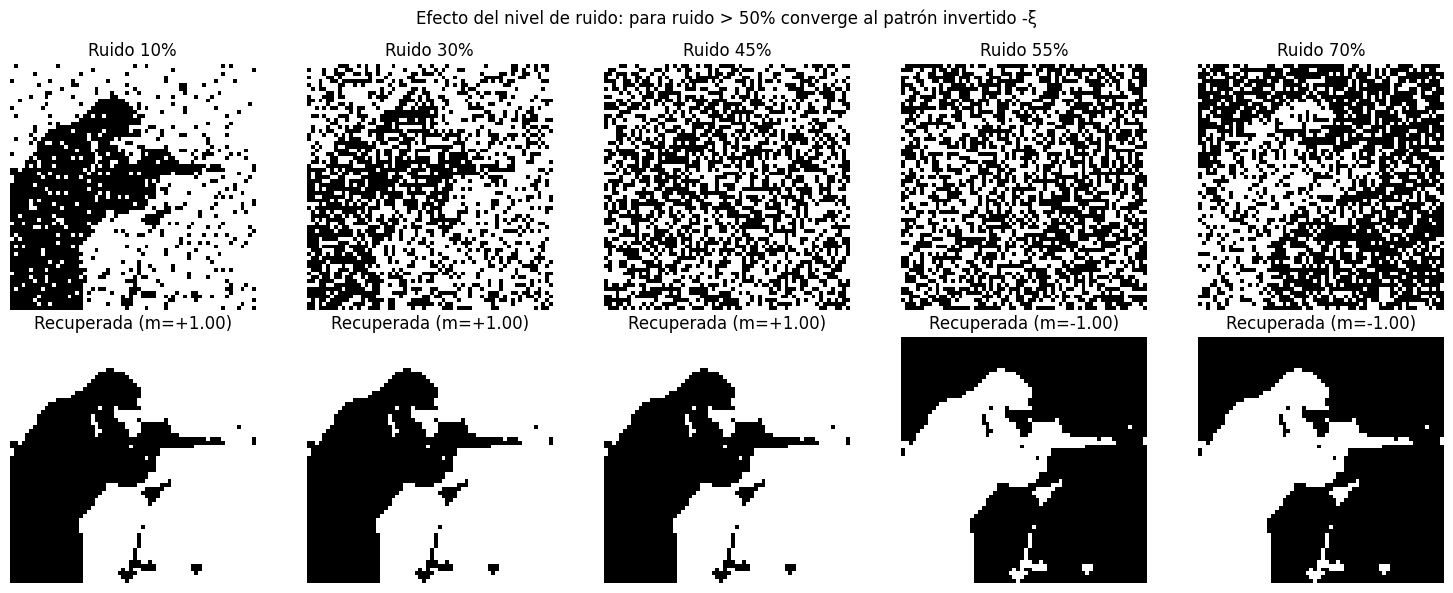

In [21]:
# ============================================================
# Experimento 1: Efecto del nivel de ruido en la recuperación
# ============================================================
niveles_ruido = [0.10, 0.30, 0.45, 0.55, 0.70]

fig, axes = plt.subplots(2, len(niveles_ruido), figsize=(15, 6))
for col, frac in enumerate(niveles_ruido):
    s_pert = aplicar_ruido(xi_camera, frac=frac, seed=100 + col)
    s_out, _, _, _ = recuperar_asincronico(W_camera, s_pert, max_epocas=5, seed=42)
    m_val = solapamiento(xi_camera, s_out)

    axes[0, col].imshow(estado_a_imagen(s_pert, (n, m)), cmap="gray", vmin=-1, vmax=1)
    axes[0, col].set_title(f"Ruido {frac*100:.0f}%")
    axes[0, col].axis("off")

    axes[1, col].imshow(estado_a_imagen(s_out, (n, m)), cmap="gray", vmin=-1, vmax=1)
    axes[1, col].set_title(f"Recuperada (m={m_val:+.2f})")
    axes[1, col].axis("off")

plt.suptitle("Efecto del nivel de ruido: para ruido > 50% converge al patrón invertido -ξ")
plt.tight_layout()
plt.show()

Matriz de solapamiento (correlación) entre los 4 patrones almacenados:
[[ 1.     0.17   0.246 -0.358]
 [ 0.17   1.     0.132  0.073]
 [ 0.246  0.132  1.    -0.115]
 [-0.358  0.073 -0.115  1.   ]]


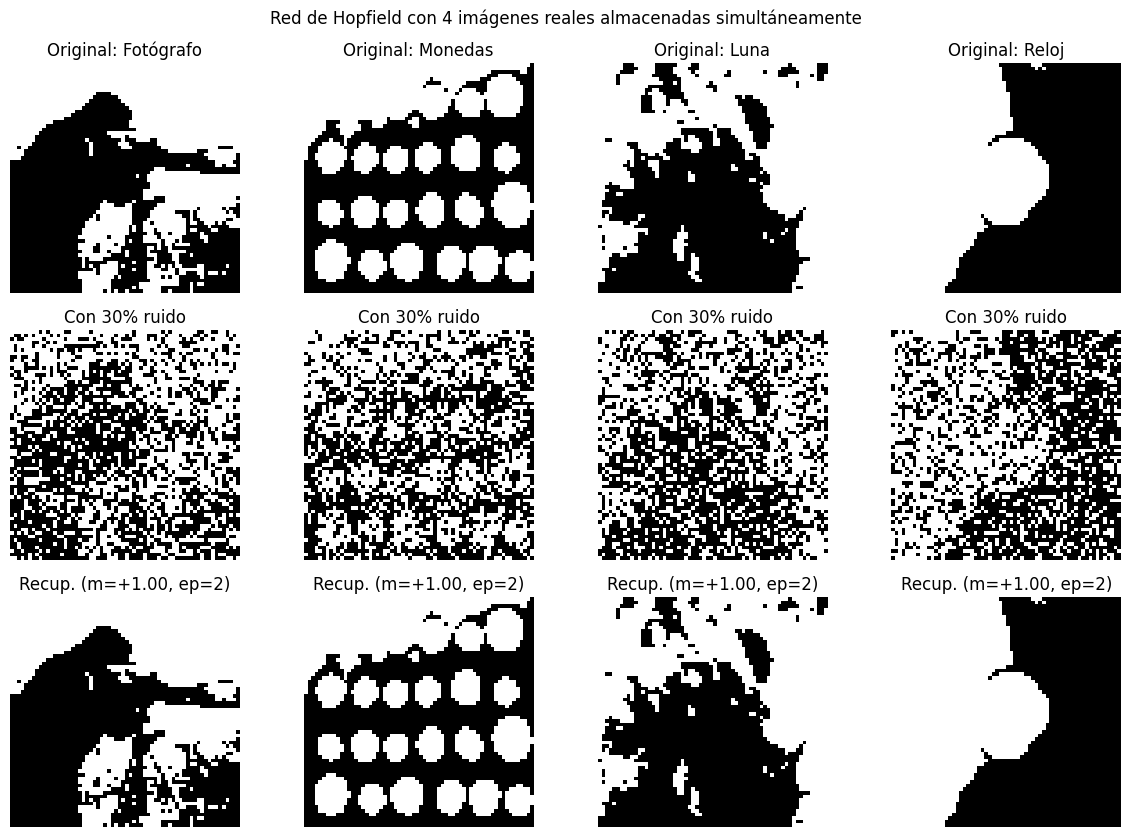

Solapamientos del atractor espurio con los 4 patrones: {'Fotógrafo': 0.642, 'Monedas': 0.528, 'Luna': 0.604, 'Reloj': -0.203}


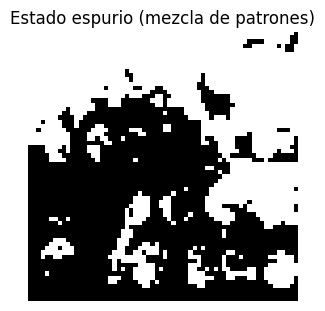

In [22]:
# ============================================================
# Experimento 2: Almacenamiento de múltiples imágenes reales
# ============================================================
def preparar_imagen_binaria(imagen, n=64, m=64):
    if imagen.ndim == 3:
        imagen = rgb2gray(imagen)
    img_r = resize(imagen.astype(float), (n, m), anti_aliasing=True)
    umbral = np.median(img_r)
    return np.where(img_r > umbral, 1.0, -1.0)


nombres = ["Fotógrafo", "Monedas", "Luna", "Reloj"]
imagenes_raw = [data.camera(), data.coins(), data.moon(), data.clock()]
patrones_multi = [imagen_a_estado(preparar_imagen_binaria(im, n, m)) for im in imagenes_raw]

# Entrenamos una única red con los 4 patrones
W_multi = matriz_pesos_hopfield(patrones_multi)

# Mostramos las correlaciones entre patrones reales
corr_mat = (np.array(patrones_multi) @ np.array(patrones_multi).T) / (n * m)
print("Matriz de solapamiento (correlación) entre los 4 patrones almacenados:")
print(np.round(corr_mat, 3))

# Intentamos recuperar cada imagen desde una versión con 30% de ruido
fig, axes = plt.subplots(3, len(nombres), figsize=(12, 8.5))
for col, (nombre, xi) in enumerate(zip(nombres, patrones_multi)):
    s_pert = aplicar_ruido(xi, frac=0.30, seed=7 + col)
    s_out, _, _, info_m = recuperar_asincronico(W_multi, s_pert, max_epocas=10, seed=42)
    m_val = solapamiento(xi, s_out)

    axes[0, col].imshow(estado_a_imagen(xi, (n, m)), cmap="gray", vmin=-1, vmax=1)
    axes[0, col].set_title(f"Original: {nombre}")
    axes[0, col].axis("off")

    axes[1, col].imshow(estado_a_imagen(s_pert, (n, m)), cmap="gray", vmin=-1, vmax=1)
    axes[1, col].set_title("Con 30% ruido")
    axes[1, col].axis("off")

    axes[2, col].imshow(estado_a_imagen(s_out, (n, m)), cmap="gray", vmin=-1, vmax=1)
    axes[2, col].set_title(f"Recup. (m={m_val:+.2f}, ep={info_m['epocas']})")
    axes[2, col].axis("off")

plt.suptitle("Red de Hopfield con 4 imágenes reales almacenadas simultáneamente")
plt.tight_layout()
plt.show()

# Ejemplo de estado espurio (mezcla de 3 patrones)
s_mezcla = np.where(patrones_multi[0] + patrones_multi[1] + patrones_multi[2] >= 0, 1.0, -1.0)
s_espurio, _, _, _ = recuperar_asincronico(W_multi, s_mezcla, max_epocas=10, seed=42)
solap_espurio = [round(solapamiento(xi, s_espurio), 3) for xi in patrones_multi]
print("Solapamientos del atractor espurio con los 4 patrones:", dict(zip(nombres, solap_espurio)))

plt.figure(figsize=(3.5, 3.5))
plt.imshow(estado_a_imagen(s_espurio, (n, m)), cmap="gray", vmin=-1, vmax=1)
plt.title("Estado espurio (mezcla de patrones)")
plt.axis("off")
plt.show()

In [23]:
# ============================================================
# Experimento 3: Actualización sincrónica vs. asincrónica
# ============================================================
def recuperar_sincronico(W, s_inicial, max_iter=20):
    s = np.asarray(s_inicial, dtype=np.float64).copy().ravel()
    energias = [energia_total(W, s)]
    for _ in range(max_iter):
        h = W @ s
        s_nuevo = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))
        energias.append(energia_total(W, s_nuevo))
        if np.array_equal(s_nuevo, s):
            s = s_nuevo
            break
        s = s_nuevo
    return s, np.array(energias)


s_test = aplicar_ruido(patrones_multi[0], frac=0.30, seed=123)
s_sinc, E_sinc = recuperar_sincronico(W_multi, s_test, max_iter=20)
s_asinc, E_asinc, _, info_a = recuperar_asincronico(W_multi, s_test, max_epocas=10, seed=42)

print(f"Sincrónica  -> pasos: {len(E_sinc)-1}, E_final: {E_sinc[-1]:.2f}, solapamiento Fotógrafo: {solapamiento(patrones_multi[0], s_sinc):.4f}")
print(f"Asincrónica -> épocas: {info_a['epocas']}, E_final: {E_asinc[-1]:.2f}, solapamiento Fotógrafo: {solapamiento(patrones_multi[0], s_asinc):.4f}")

Sincrónica  -> pasos: 2, E_final: -2492.23, solapamiento Fotógrafo: 1.0000
Asincrónica -> épocas: 2, E_final: -2492.23, solapamiento Fotógrafo: 1.0000


### Respuestas a las preguntas guía

1. **¿La energía disminuye durante la recuperación?** Sí. En actualización asincrónica, cada cambio de estado produce $\Delta E = -\Delta s_i\, h_i \le 0$, por lo que la curva de energía desciende de forma estrictamente monótona hasta alcanzar un mínimo local.
2. **¿La red recupera exactamente la imagen original?** Cuando se almacena únicamente la imagen del fotógrafo con $30\%$ de ruido, la red recupera el $100\%$ de los píxeles exactos ($m = 1.0$) y alcanza la energía teórica mínima $E(\xi) = -(N-1)/2 = -2047.5$.
3. **¿Qué ocurre si aumenta el nivel de ruido?** Para una sola imagen almacenada, mientras el ruido sea menor al $50\%$ ($m_0 > 0$), la red recupera la imagen original $\xi$. Al superar el $50\%$ ($m_0 < 0$), el estado inicial queda más cerca del patrón invertido $-\xi$ (que posee exactamente la misma energía $E(-\xi)=E(\xi)$) y la red converge al negativo de la imagen.
4. **¿Qué pasa si se almacenan varias imágenes?** Al superponer varios patrones en $W$, aparece un término de interferencia entre ellos. Como las imágenes reales no son completamente aleatorias sino que presentan correlaciones espaciales entre sí, la calidad de recuperación se degrada mucho antes del límite teórico $P_c \approx 0.138 N$ (que asume patrones aleatorios no correlacionados).
5. **¿Aparecen estados espurios?** Sí. Al almacenar varios patrones ($P \ge 3$), combinaciones de ellos como $\mathrm{sign}(\xi^1 + \xi^2 + \xi^3)$ generan mínimos locales no deseados (estados mezcla) en los que la red puede quedar atrapada, como se observa en la figura del estado espurio.
6. **¿La recuperación depende del orden en que se actualizan los píxeles?** Para un único patrón con ruido moderado no cambia el atractor final, pero cuando hay múltiples patrones y el estado inicial está cerca de la frontera entre dos cuencas de atracción, distintos órdenes aleatorios de actualización pueden llevar a mínimos locales diferentes.
7. **¿Qué diferencia hay entre actualización sincrónica y asincrónica?** La actualización asincrónica modifica una neurona a la vez usando inmediatamente el nuevo estado para calcular el siguiente campo local, lo cual garantiza $\Delta E \le 0$ y convergencia a un punto fijo. La actualización sincrónica actualiza todas las neuronas simultáneamente con $W\mathbf{s}^{(t)}$; aunque es muy rápida por iteración, puede oscilar en ciclos de periodo 2 sin estabilizarse en un único estado.